# LAB 4: Implementation of Logistic Regression for Heart Disease Prediction

## 1. Context & Problem Statement
Binary classification predicts a discrete outcome. Given patient attributes `Age, Resting_Blood_Pressure, Cholesterol, Maximum_Heart_Rate, Exercise_Induced_Angina` and a binary target `Heart_Disease` (1 = present, 0 = absent), the objectives are to:
1. **Model P(Y=1|X)** with the sigmoid function $\sigma(z)=\frac{1}{1+e^{-z}}$, $z=\beta_0+\beta_1X_1+\dots+\beta_pX_p$, trained by minimising binary cross-entropy.
2. **Evaluate** on a stratified 80:20 split with accuracy, precision, recall, F1, ROC-AUC and the confusion matrix.
3. **Analyse the decision threshold** (0.50 default vs lower thresholds that favour recall in clinical screening).

| Component | Specification |
|---|---|
| Model | Binary Logistic Regression (sigmoid link) |
| Target | `Heart_Disease` (0 = absent, 1 = present) |
| Features | Age, Resting_Blood_Pressure, Cholesterol, Maximum_Heart_Rate, Exercise_Induced_Angina |
| Metrics | Accuracy, Precision, Recall, F1, ROC-AUC, Confusion Matrix |

## 2. Implementation
### Step 1: Load the dataset (`heart_disease_data.csv`, same folder)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

sns.set_theme(style="whitegrid")
data = pd.read_csv("heart_disease_data.csv")
print("Shape:", data.shape)
display(data.head())

Shape: (50, 6)


,Age,Resting_Blood_Pressure,Cholesterol,Maximum_Heart_Rate,Exercise_Induced_Angina,Heart_Disease
0,63,145,233,150,0,1
1,67,160,286,108,1,0
2,67,120,229,129,1,0
3,37,130,250,187,0,1
4,41,130,204,172,0,1


### Step 2: Data quality check and class balance

Missing values:
Age                        0
Resting_Blood_Pressure     0
Cholesterol                0
Maximum_Heart_Rate         0
Exercise_Induced_Angina    0
Heart_Disease              0
dtype: int64

Duplicate rows: 1
Duplicates dropped, new shape: (49, 6)

Class balance (0 = No Disease, 1 = Disease):
Heart_Disease
1    28
0    21
Name: count, dtype: int64


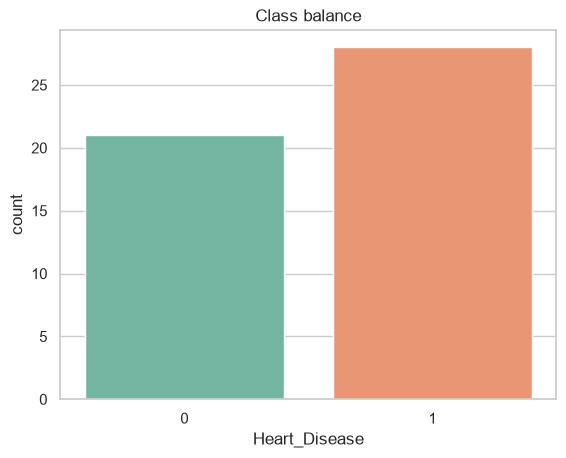

In [2]:
print("Missing values:\n", data.isnull().sum(), sep="")
dups = int(data.duplicated().sum())
print(f"\nDuplicate rows: {dups}")
if dups:
    data = data.drop_duplicates().reset_index(drop=True)   # a duplicate could leak between train and test
    print("Duplicates dropped, new shape:", data.shape)
print("\nClass balance (0 = No Disease, 1 = Disease):")
print(data["Heart_Disease"].value_counts())
sns.countplot(data=data, x="Heart_Disease", hue="Heart_Disease", palette="Set2", legend=False); plt.title("Class balance"); plt.show()

### Step 3: Stratified train-test split (80:20)

In [3]:
features = ["Age", "Resting_Blood_Pressure", "Cholesterol", "Maximum_Heart_Rate", "Exercise_Induced_Angina"]
X = data[features]
y = data["Heart_Disease"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print(f"Training samples: {len(X_train)}   Testing samples: {len(X_test)}")

Training samples: 39   Testing samples: 10


### Step 4 & 5: Standardise features and train the model

In [4]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit on training data only
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)
print("Model trained.")

Model trained.


### Step 6 & 7: Predictions and evaluation metrics

In [5]:
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

print("Model Performance")
print("-----------------")
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-Score :", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:\n", cm)

Model Performance
-----------------
Accuracy : 0.9
Precision: 0.8571
Recall   : 1.0
F1-Score : 0.9231
ROC-AUC  : 0.9583

Confusion Matrix:
 [[3 1]
 [0 6]]


### Step 8 & 9: Confusion matrix, ROC curve and probability distribution

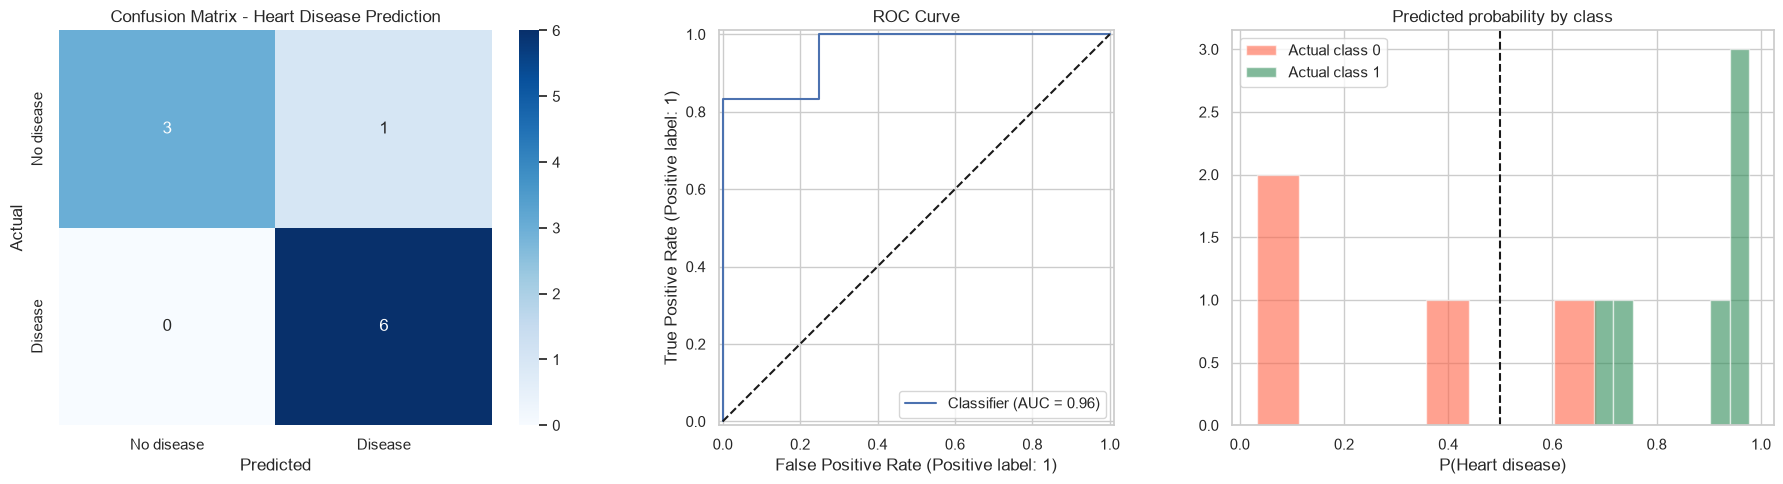

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0], xticklabels=["No disease", "Disease"], yticklabels=["No disease", "Disease"])
axes[0].set_title("Confusion Matrix - Heart Disease Prediction"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1]); axes[1].plot([0, 1], [0, 1], "k--"); axes[1].set_title("ROC Curve")
for cls, col in [(0, "tomato"), (1, "seagreen")]:
    axes[2].hist(y_prob[y_test.values == cls], bins=8, alpha=.6, color=col, label=f"Actual class {cls}")
axes[2].axvline(0.5, color="k", ls="--"); axes[2].set_title("Predicted probability by class"); axes[2].set_xlabel("P(Heart disease)"); axes[2].legend()
plt.tight_layout(); plt.show()

### Step 10: Learned coefficients
Coefficients are on standardised features, so their magnitudes are directly comparable. Positive values raise the log-odds of heart disease.

In [7]:
coeffs = pd.DataFrame({"Feature": features, "Coefficient": model.coef_[0], "Odds ratio": np.exp(model.coef_[0])})
display(coeffs.sort_values("Coefficient", ascending=False).round(4))
print("Intercept:", round(float(model.intercept_[0]), 4))

,Feature,Coefficient,Odds ratio
3,Maximum_Heart_Rate,1.0901,2.9746
2,Cholesterol,0.3027,1.3536
1,Resting_Blood_Pressure,-0.0792,0.9238
0,Age,-0.2786,0.7569
4,Exercise_Induced_Angina,-1.2767,0.2790


Intercept: 0.2423


### Step 11: Decision-threshold analysis (clinical screening)
Lowering the threshold below 0.50 detects more true patients (higher recall) at the cost of more false alarms (lower precision).

In [8]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred_t = (y_prob >= t).astype(int)
    rows.append({"Threshold": t,
                 "Accuracy": accuracy_score(y_test, pred_t),
                 "Precision": precision_score(y_test, pred_t, zero_division=0),
                 "Recall": recall_score(y_test, pred_t, zero_division=0),
                 "F1": f1_score(y_test, pred_t, zero_division=0)})
display(pd.DataFrame(rows).round(4))

,Threshold,Accuracy,Precision,Recall,F1
0,0.3,0.8,0.7500,1.0000,0.8571
1,0.4,0.8,0.7500,1.0000,0.8571
2,0.5,0.9,0.8571,1.0000,0.9231
3,0.6,0.9,0.8571,1.0000,0.9231
4,0.7,0.9,1.0000,0.8333,0.9091


### Step 12: Predict for a new patient

In [9]:
new_patient = pd.DataFrame([{"Age": 55, "Resting_Blood_Pressure": 140, "Cholesterol": 240,
                             "Maximum_Heart_Rate": 150, "Exercise_Induced_Angina": 1}])
new_scaled = scaler.transform(new_patient)
prediction = model.predict(new_scaled)[0]
probability = model.predict_proba(new_scaled)[0, 1]
print("New Patient Prediction")
print("----------------------")
print("Probability of Heart Disease:", round(float(probability), 4))
print("Prediction:", "Heart Disease Present" if prediction == 1 else "No Heart Disease")

New Patient Prediction
----------------------
Probability of Heart Disease: 0.1775
Prediction: No Heart Disease


## 3. Interpretation of results
A predicted probability of 0.50 or more is classified as *Heart Disease Present*. For clinical screening **recall (sensitivity)** matters most, because a missed patient (false negative) is costlier than a false alarm, so the threshold can be lowered when higher sensitivity is required.

**Note:** the supplied dataset has only ~49 distinct patients, so the test set holds about 10 rows and every metric moves in steps of 10%; treat the numbers as indicative, not definitive.

## 4. Conclusion
A logistic regression model on five clinical features was trained with a stratified split and standardised inputs, evaluated with accuracy, precision, recall, F1, ROC-AUC, a confusion-matrix heatmap and probability plots, and its decision threshold was analysed for a recall-oriented screening scenario.